# Correlation between affinity and binding scores for c259 TCR binding peptide mutants

In [1]:
import os
import subprocess
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from scipy.stats import pearsonr

In [2]:
AFFINITY_CUTOFF = 100  # uM

In [3]:
sequences = pd.read_csv('../data/interim/sequences_c259_mutational_scan_affinity.csv', index_col='id')
sequences = sequences.drop_duplicates('peptide')

In [4]:
sequences.loc[sequences['geometric_mean'] > AFFINITY_CUTOFF, 'geometric_mean'] = np.inf
sequences['geometric_mean'] = sequences['geometric_mean'].fillna(np.inf)
sequences['affinity_norm'] = sequences['geometric_mean'].min() / sequences['geometric_mean']

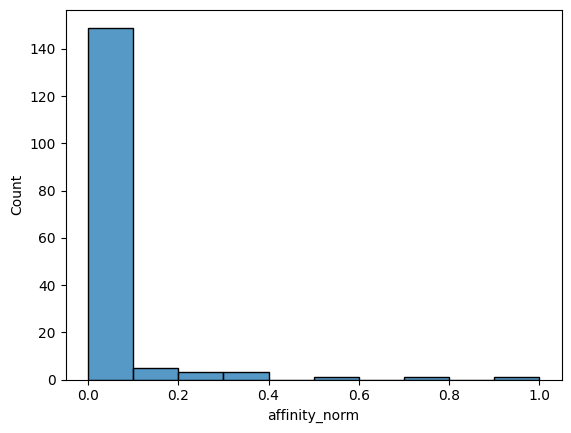

In [5]:
sns.histplot(sequences, x='affinity_norm', bins=10)
plt.show()

In [6]:
NETMHCPAN_BINDER_CUTOFF = 2.0

In [7]:
with tempfile.TemporaryDirectory() as temp_dir:
    input_name = os.path.join(temp_dir, 'peptides.fasta')
    with open(input_name, 'w') as fh:
        fh.writelines(f'>{id_}\n{sequence}\n' for id_, sequence in sequences['peptide'].to_dict().items())

    output_name = os.path.join(temp_dir, 'out.tsv')
    subprocess.run(  # noqa: S603
        ['/usr/bin/env', 'netMHCpan', '-xls', '-xlsfile', output_name, '-a', 'HLA-A02:01', input_name],
        check=True,
        stdout=subprocess.DEVNULL,
    )

    netmhcpan_predictions = pd.read_csv(output_name, delimiter='\t', comment='#', header=1)

netmhcpan_predictions.columns = [column_name.lower() for column_name in netmhcpan_predictions.columns]
netmhcpan_predictions['id'] = netmhcpan_predictions['id'].replace('c259_original_9', 'c259_original_9V')
netmhcpan_predictions = netmhcpan_predictions.set_index('id')

sequences = pd.concat([sequences, netmhcpan_predictions[['el_rank']]], axis=1)

In [8]:
to_be_screened = set(
    sequences[np.isinf(sequences['geometric_mean']) & (sequences['el_rank'] > NETMHCPAN_BINDER_CUTOFF)].index
)

In [9]:
non_binders = set(sequences[sequences['el_rank'] > NETMHCPAN_BINDER_CUTOFF].index)
print('IDs not reported to bind from NetMHCpan but have affinity data:', ', '.join(non_binders - to_be_screened))

IDs not reported to bind from NetMHCpan but have affinity data: c259_9W, c259_2Y, c259_6W, c259_1D, c259_2W


In [10]:
no_affinity = set(sequences[np.isinf(sequences['geometric_mean'])].index)
print("IDs that don't have affinity data but are pMHC binders:\n\n\t-", '\n\t- '.join(no_affinity - to_be_screened))

IDs that don't have affinity data but are pMHC binders:

	- c259_4G
	- c259_8T
	- c259_1E
	- c259_7R
	- c259_8R
	- c259_8V
	- c259_5T
	- c259_5P
	- c259_7F
	- c259_7V
	- c259_5Q
	- c259_5M
	- c259_4P
	- c259_3E
	- c259_4E
	- c259_8L
	- c259_4H
	- c259_8Y
	- c259_5G
	- c259_3G
	- c259_5N
	- c259_6D
	- c259_3P
	- c259_8P
	- c259_9M
	- c259_5F
	- c259_5I
	- c259_8D
	- c259_7L
	- c259_8S
	- c259_8K
	- c259_6E
	- c259_8M
	- c259_8I
	- c259_4Y
	- c259_7K
	- c259_1M
	- c259_4F
	- c259_6K
	- c259_6R
	- c259_3K
	- c259_5H
	- c259_5L
	- c259_8A
	- c259_5K
	- c259_5Y
	- c259_8W
	- c259_4R
	- c259_5S
	- c259_4A
	- c259_3R
	- c259_5D
	- c259_8N
	- c259_7Y
	- c259_3D
	- c259_8F
	- c259_4W
	- c259_8E
	- c259_7W
	- c259_7I
	- c259_7M
	- c259_6G
	- c259_5R
	- c259_5V
	- c259_2T
	- c259_5A
	- c259_5E


In [11]:
sequences_remove_non_binders = sequences[~sequences.index.isin(to_be_screened)]

In [12]:
binding_scores = pd.read_csv(
    '../data/processed/af3_af3_tcrmodel2_c259_mutational_scan_affinity_pae_aggregator_predictions.csv'
)
binding_scores['prediction'] = binding_scores[
    ['prediction_1', 'prediction_2', 'prediction_3', 'prediction_4', 'prediction_5']
].apply('median', axis=1)

binding_scores = binding_scores.merge(sequences_remove_non_binders, how='inner', left_on='name', right_index=True)

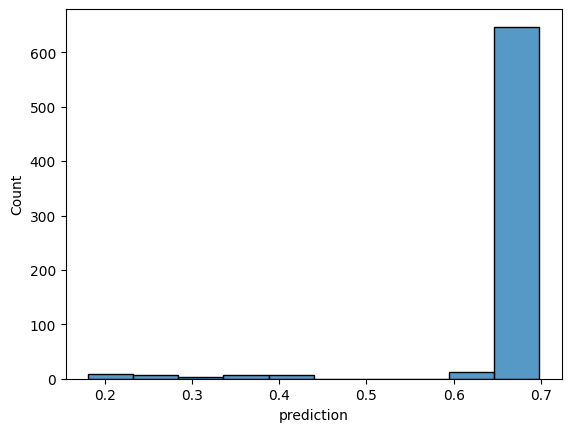

In [13]:
sns.histplot(binding_scores, x='prediction', bins=10)
plt.show()

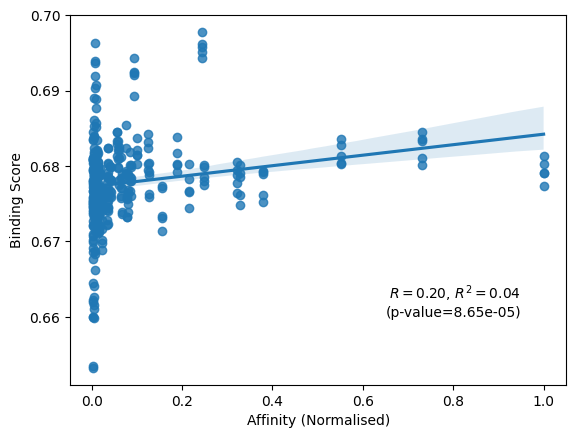

In [14]:
ax = sns.regplot(binding_scores[~np.isinf(binding_scores['geometric_mean'])], x='affinity_norm', y='prediction')

r, p_val = pearsonr(
    binding_scores.loc[~np.isinf(binding_scores['geometric_mean']), 'affinity_norm'],
    binding_scores.loc[~np.isinf(binding_scores['geometric_mean']), 'prediction'],
    alternative='greater',
)
ax.text(0.95, 0.66, f'$R={r:.2f}$, $R^2={r**2:.2f}$\n(p-value={p_val:.2e})', ha='right')

ax.set_ylabel('Binding Score')
ax.set_xlabel('Affinity (Normalised)')

plt.savefig('../report/figures/c259_binding_score_affinity_regression.svg')
plt.show()

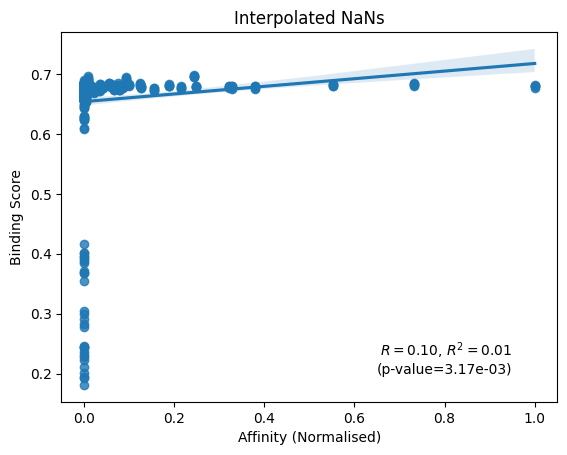

In [15]:
ax = sns.regplot(binding_scores, x='affinity_norm', y='prediction')

r, p_val = pearsonr(binding_scores['affinity_norm'], binding_scores['prediction'], alternative='greater')
ax.text(0.95, 0.2, f'$R={r:.2f}$, $R^2={r**2:.2f}$\n(p-value={p_val:.2e})', ha='right')

ax.set_ylabel('Binding Score')
ax.set_xlabel('Affinity (Normalised)')
ax.set_title('Interpolated NaNs')

plt.show()

In [16]:
binding_scores['status'] = 'Binder'
binding_scores.loc[np.isinf(binding_scores['geometric_mean']), 'status'] = 'Non-Binder'

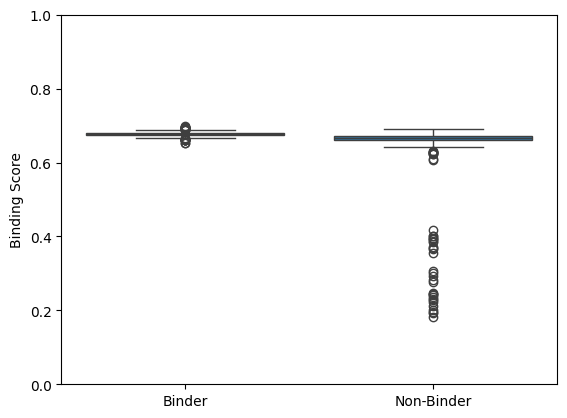

In [17]:
ax = sns.boxplot(binding_scores, y='prediction', x='status')

ax.set_ylim(0, 1)

ax.set_xlabel('')
ax.set_ylabel('Binding Score')

plt.savefig('../report/figures/tcr_c259_affinity_disruption_boxplot.svg')
plt.show()

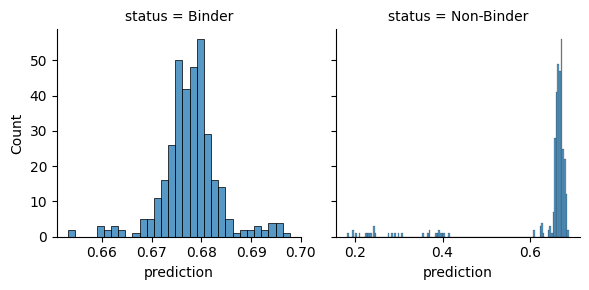

In [18]:
grid = sns.FacetGrid(binding_scores, col='status', sharex=False)
grid.map_dataframe(sns.histplot, x='prediction')

plt.show()

In [19]:
pg.ttest(
    binding_scores.query("status == 'Binder'")['prediction'],
    binding_scores.query("status == 'Non-Binder'")['prediction'],
    alternative='greater',
)

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,7.369234,335.884277,greater,6.719727e-13,"[0.03, inf]",0.577758,2.461e+10,1.0
